## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

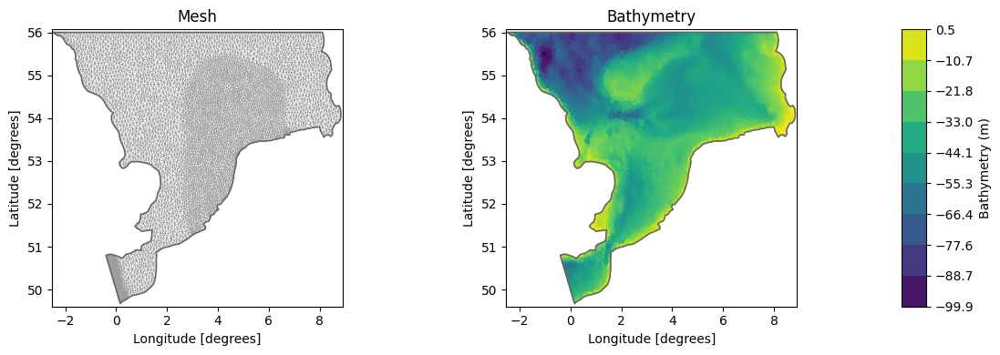

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

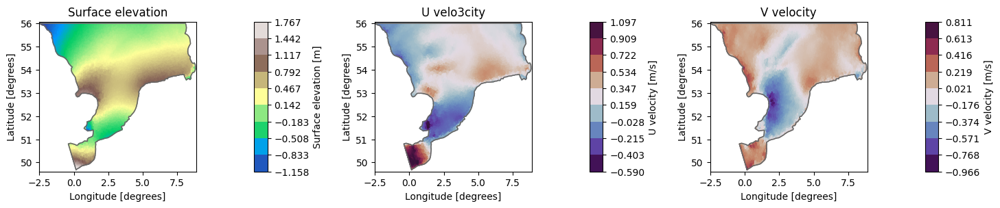

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


## Available Sensors

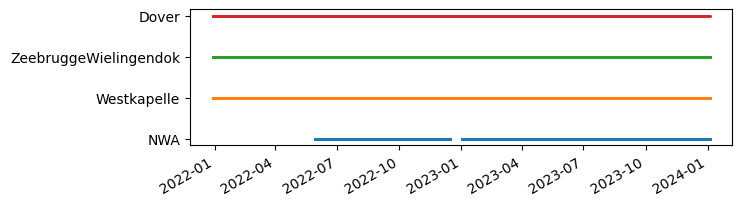

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
#altlist = get_altimetry_obs()

high_fidelity = ["Dover", "ZeebruggeWielingendok", "Westkapelle", "NWA"]

alllist = wllist #+ altlist
alllist = [obs for obs in alllist if obs.name in high_fidelity]
ms.plotting.temporal_coverage(alllist)
plt.show()

Total stations: 4
Stations with full temporal coverage: 2
Intermittent stations: 2


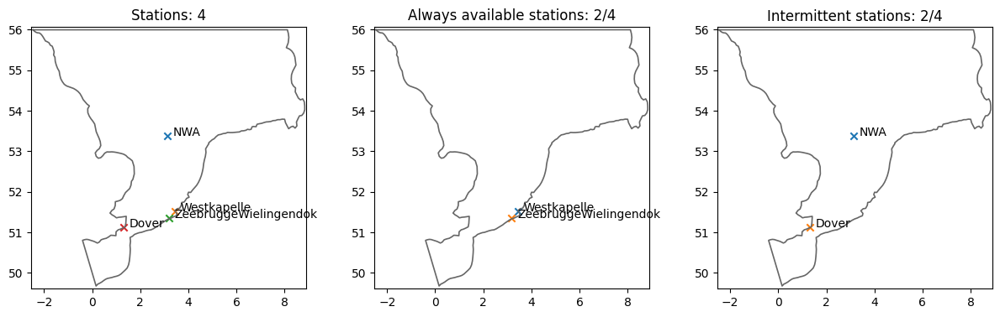

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        availables.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(availables)}")
print(f"Intermittent stations: {len(intermittent)}")

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 4])


In [10]:
ERRORS = []

In [11]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (2):


,station,ok,nans,coverage_%
0,NWA,"26,469","8,570",75.5
1,Dover,"17,024","18,015",48.6


## Idea T.0: Only Available Sensors

In [12]:
# Keep only sensors that never contain NaNs over time
nan_sensor_mask = torch.isnan(measurements).any(dim=0)
measurements_av = measurements[:, ~nan_sensor_mask]

kept_sensor_indices = torch.where(~nan_sensor_mask)[0]
removed_sensor_indices = torch.where(nan_sensor_mask)[0]

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)


After selecting always-available stations only:
H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 2])


Nuber of nan values in measurements after imputation: 0 



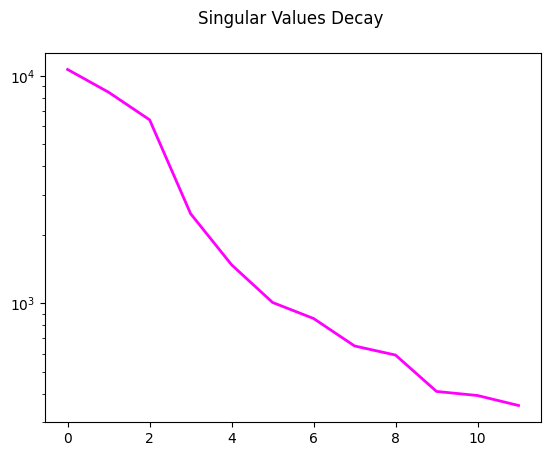

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %


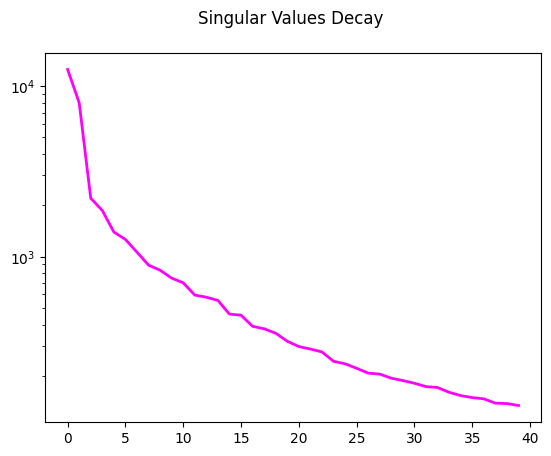

Residual energy of U velocity after keeping 40 modes: 0.1947 %


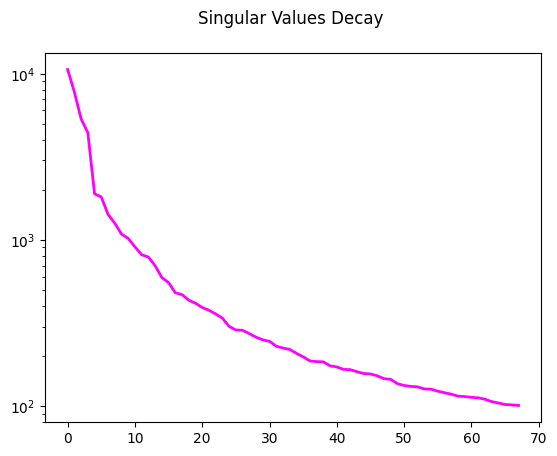

Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 2]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 2]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 2]) -> torch.Size([3504, 120])

Input shape for the model: 2
Output shape for the model: 120


In [13]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements_av, verbose = True)
manager.add_data(U, id = "U velocity", compress = 40, verbose = True)
manager.add_data(V, id = "V velocity", compress = 68, verbose = True)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Starting training...


Training: 100%|██████████| 200/200 [30:33<00:00,  9.17s/it, Train Loss=0.0046, Val Loss=0.0047, Patience=23, Best Val Loss=0.0047, LR=0.00e+00]

Training completed with best validation loss: 0.0047


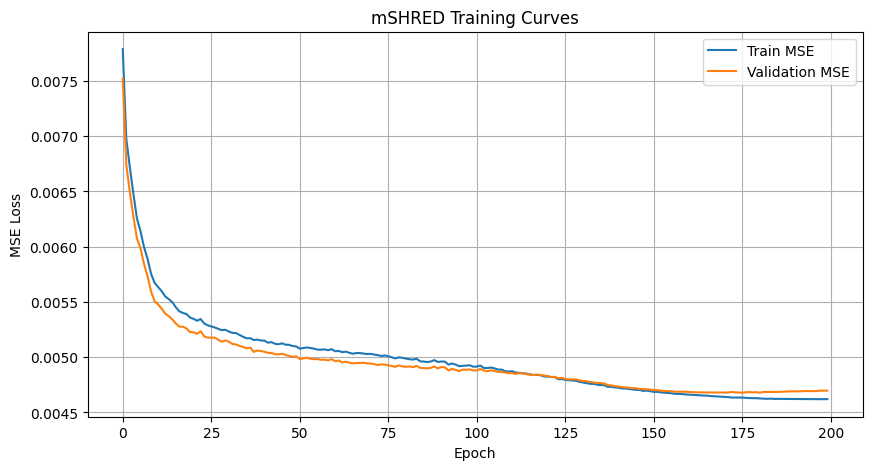

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.13557,0.135086,0.208547


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels = False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_0_only_available_sensors.png


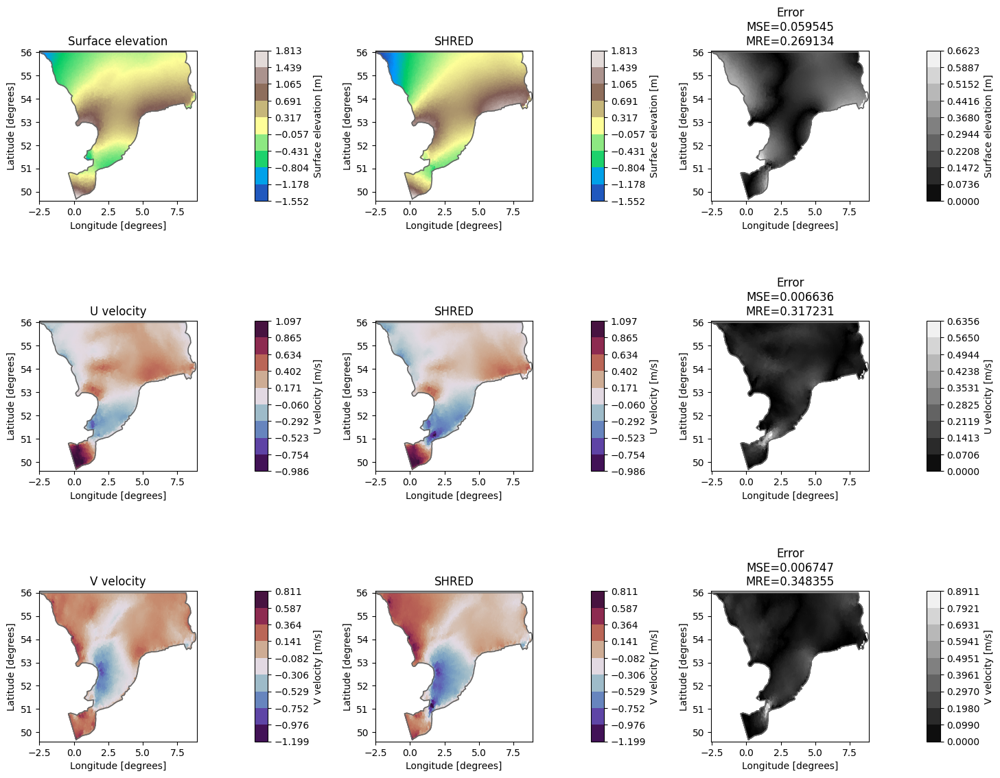

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_0_only_available_sensors")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.0: Only Available Sensors

Starting training...


Training: 100%|██████████| 200/200 [09:04<00:00,  2.72s/it, Train Loss=0.0044, Val Loss=0.0045, Patience=13, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


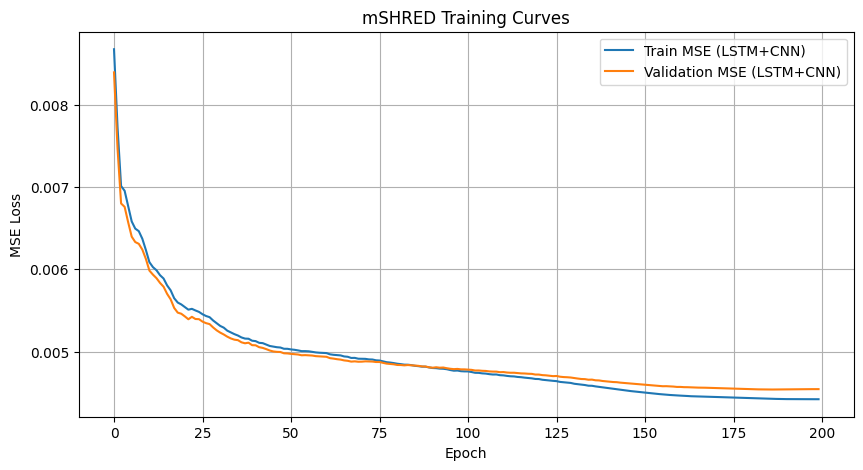

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.13557,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.13231,0.132837,0.205673


In [16]:

# mSHRED TRAINING (Idea S.0) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.0) only available sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_0_only_available_sensors.png


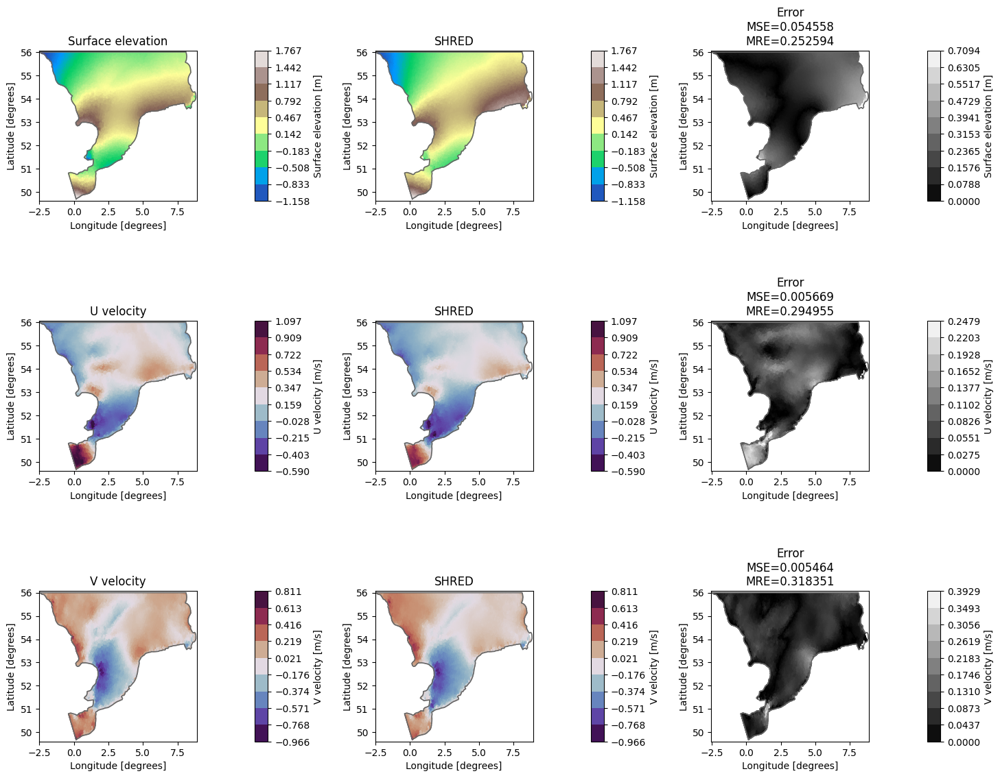

In [17]:

# SHRED RECONSTRUCTION (Idea S.0)
engine_shred = SHREDEngine(manager, mshred)
test_reconstruction_shred = engine_shred.sensor_to_reconstruction_dataset(test_dataset)
ds_shred_s0, ds_error_s0 = plot_shred_reconstruction(test_reconstruction_shred, ds, geom, title_suffix="S_0_only_available_sensors")

del engine_shred, test_reconstruction_shred, ds_shred_s0, ds_error_s0, mshred, manager


## Idea T.1.A: Median imputer

In [18]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 4]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [32:23<00:00,  9.72s/it, Train Loss=0.0045, Val Loss=0.0045, Patience=32, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


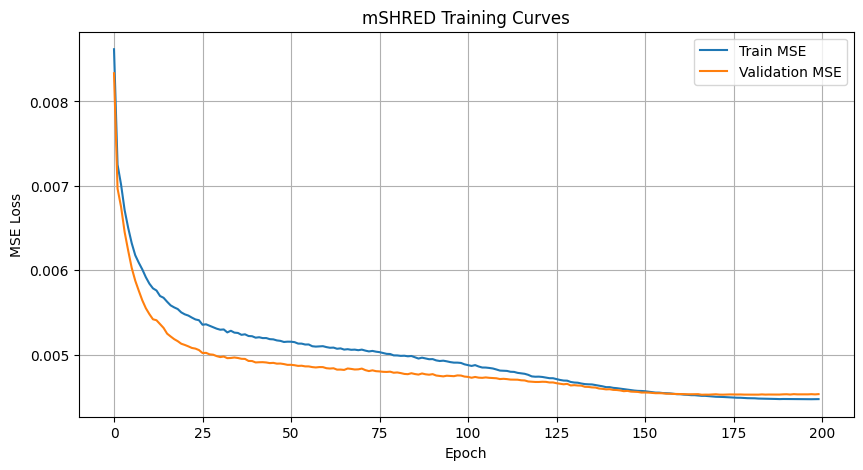

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210


In [19]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


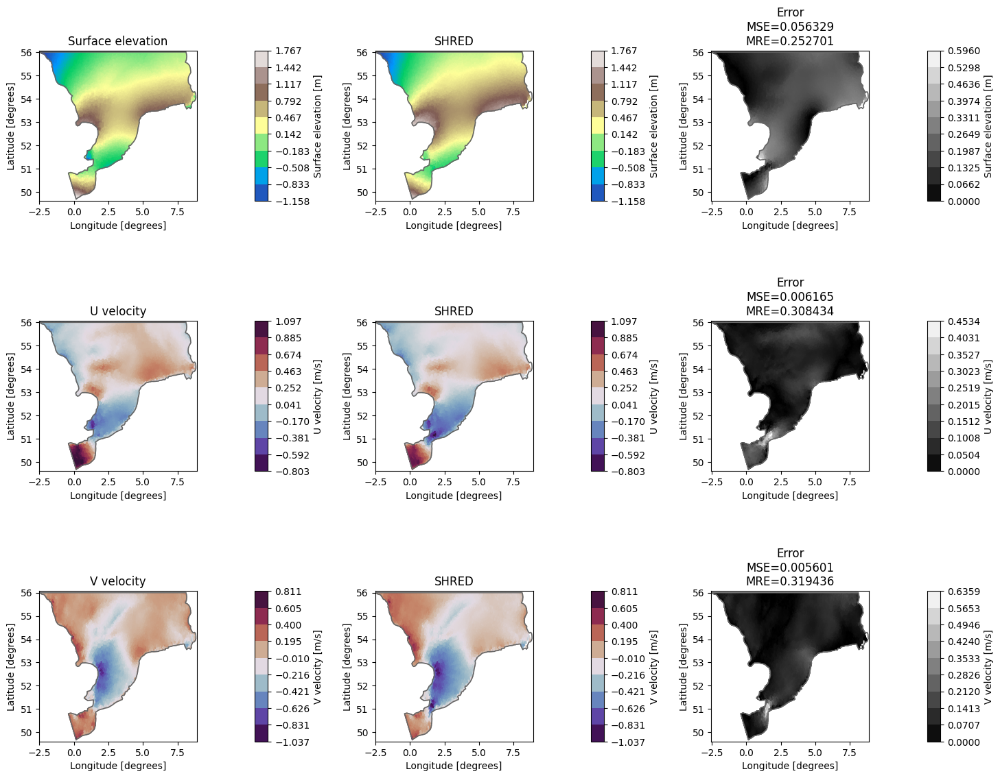

In [20]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.A: Median imputer 


Starting training...


Training: 100%|██████████| 200/200 [10:52<00:00,  3.26s/it, Train Loss=0.0043, Val Loss=0.0045, Patience=14, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


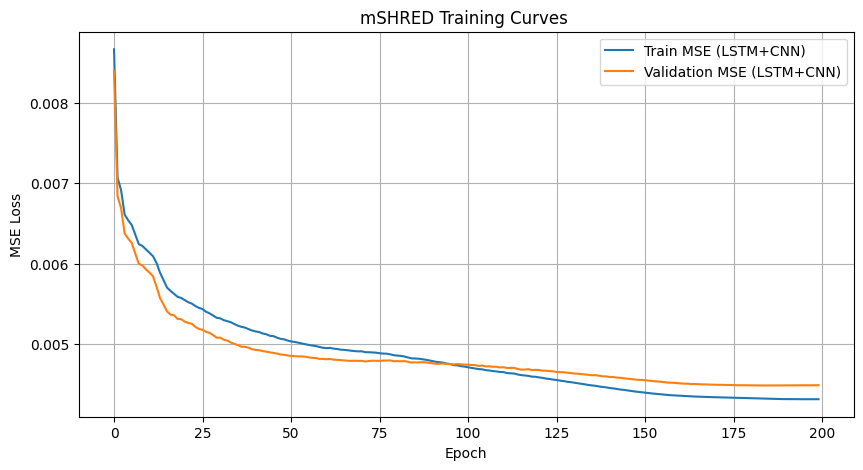

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494


In [21]:

# mSHRED TRAINING (Idea S.1.A) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_A_median_imputation.png


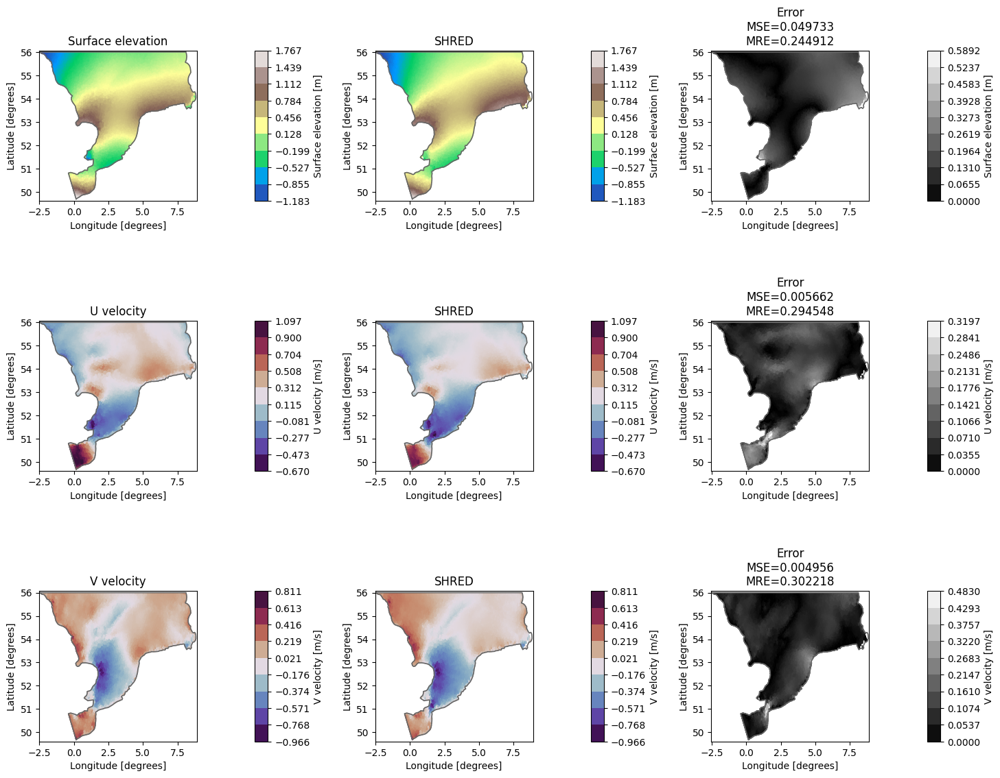

In [22]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.B: Mean imputer

In [23]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 4]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [29:20<00:00,  8.80s/it, Train Loss=0.0044, Val Loss=0.0045, Patience=4, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


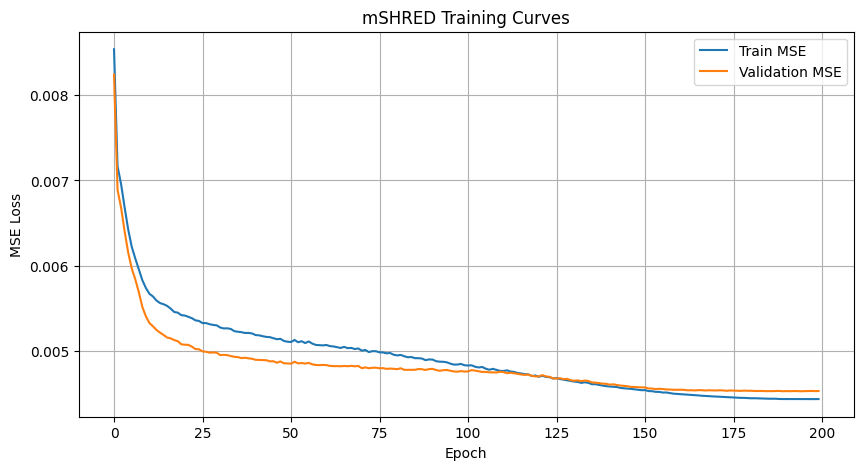

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274


In [24]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


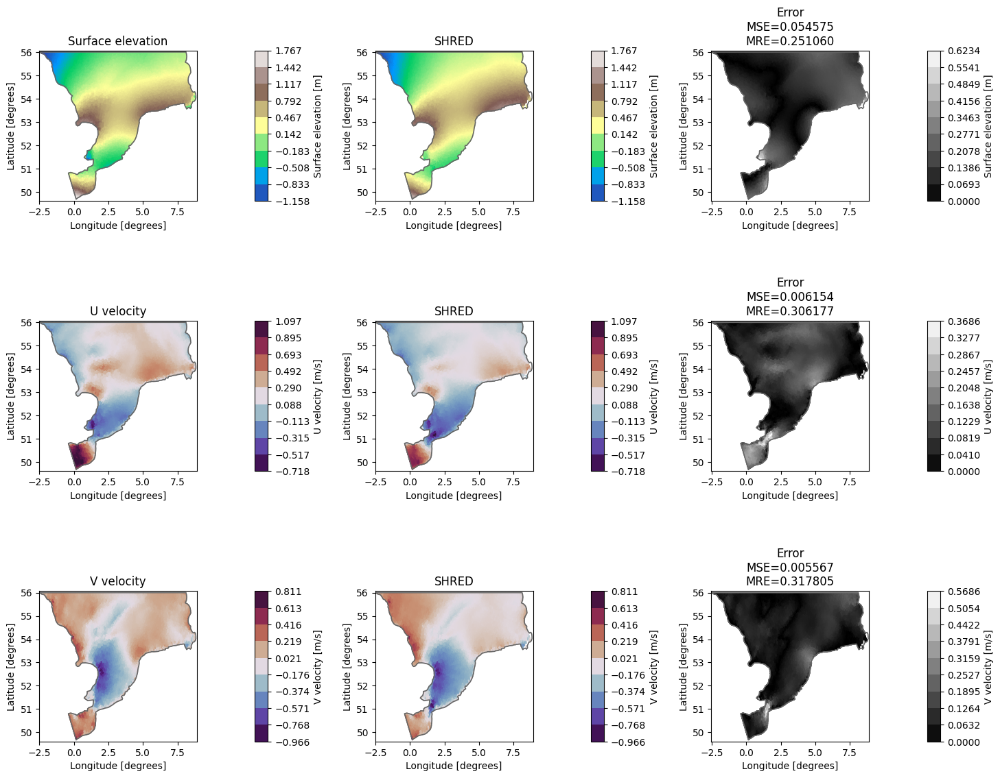

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.B: Mean imputer

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [10:27<00:00,  3.14s/it, Train Loss=0.0043, Val Loss=0.0045, Patience=16, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


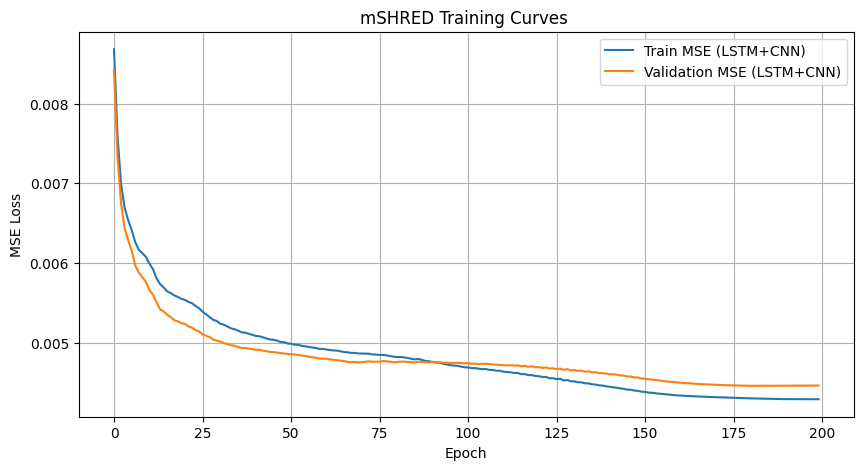

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436


In [26]:

# mSHRED TRAINING (Idea S.1.B) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_B_mean_imputation.png


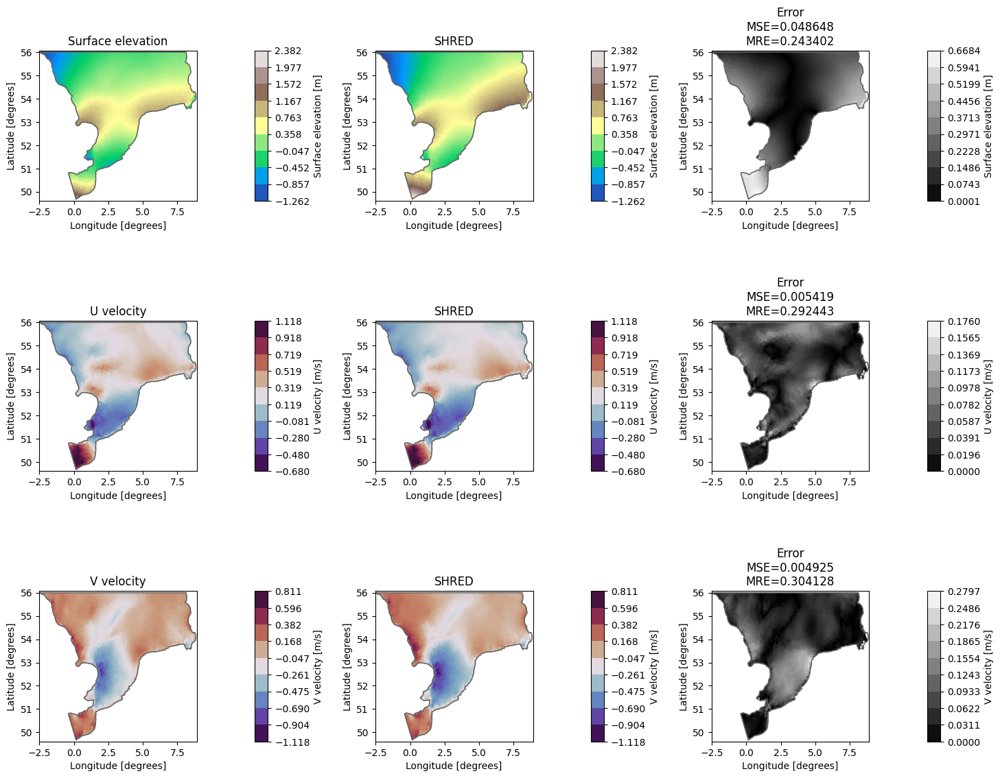

In [27]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.C: Last value imputer

In [28]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 4]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [29:54<00:00,  8.97s/it, Train Loss=0.0044, Val Loss=0.0045, Patience=28, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


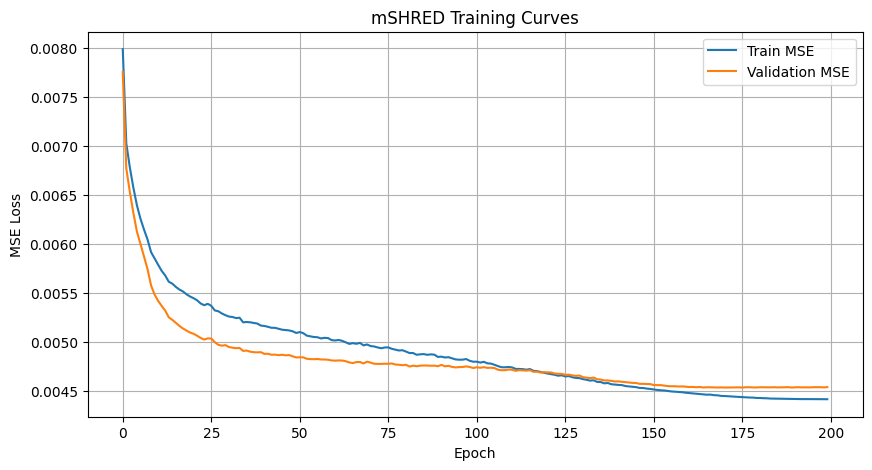

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033


In [29]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


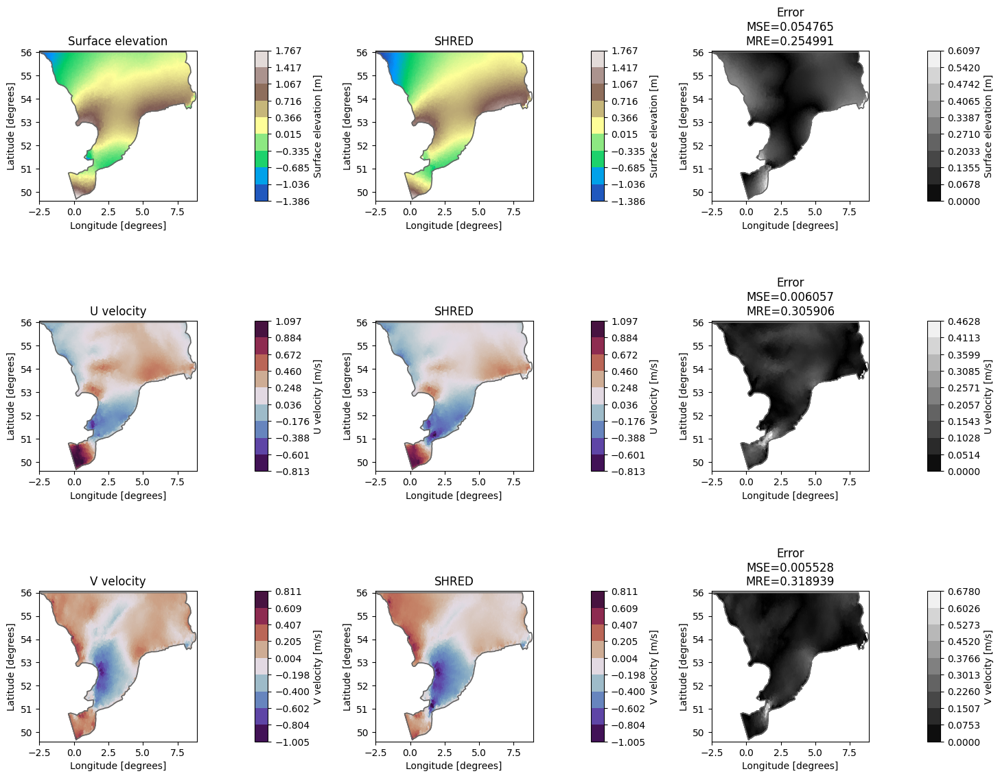

In [30]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.C: Last value imputer

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [09:06<00:00,  2.73s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=11, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


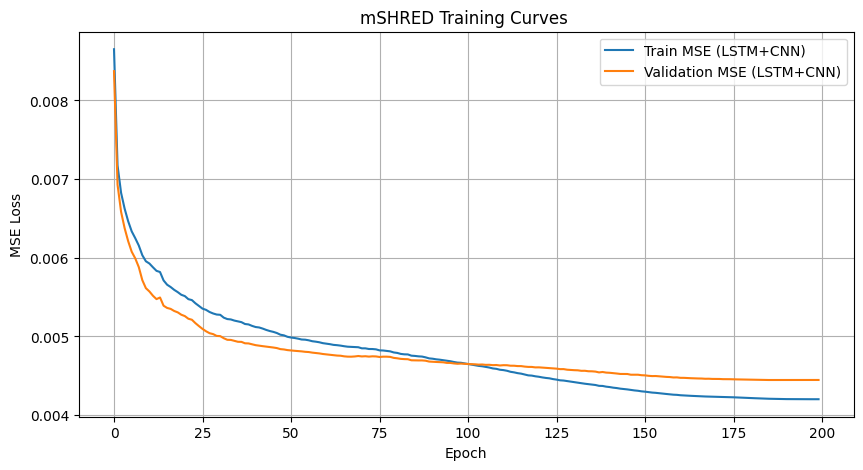

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995


In [31]:

# mSHRED TRAINING (Idea S.1.C) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_C_last_value_imputation.png


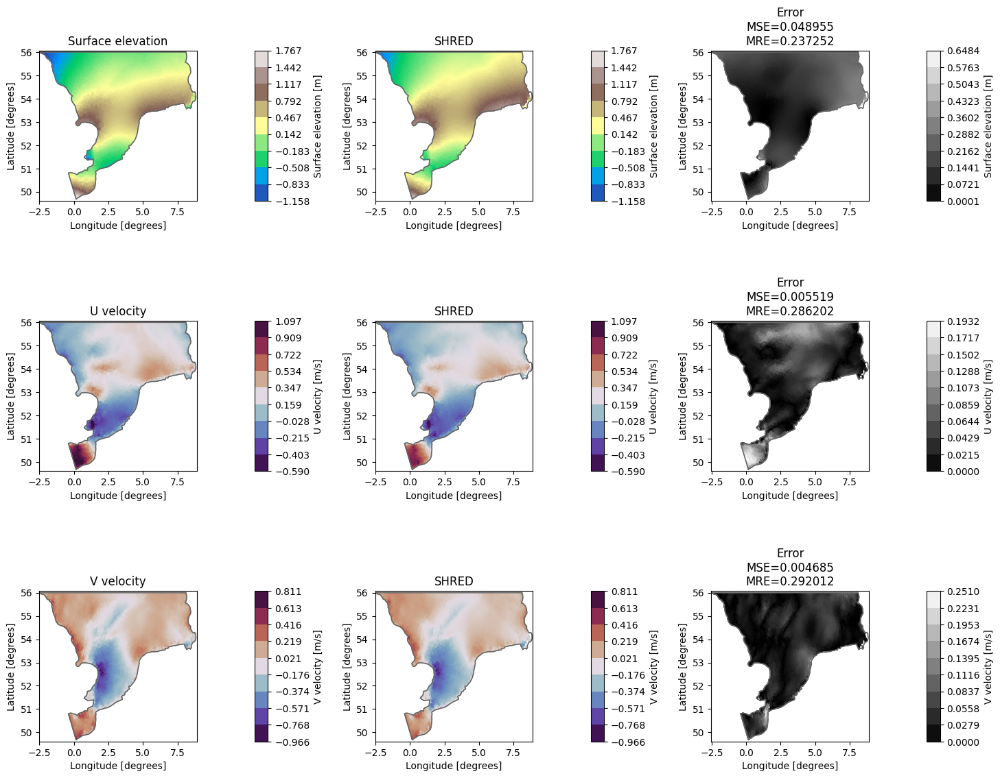

In [32]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea 2.A: GRUD

In [33]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 26585 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 4, 24, 4]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 4, 24, 4]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 4, 24, 4]) -> torch.Size([3504, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [23:05<00:00,  6.93s/it, Train Loss=0.0045, Val Loss=0.0045, Patience=23, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


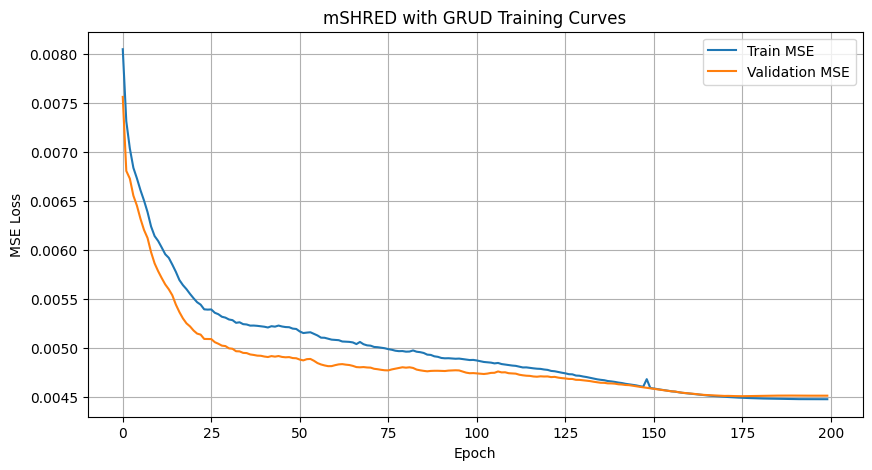

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981


In [34]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


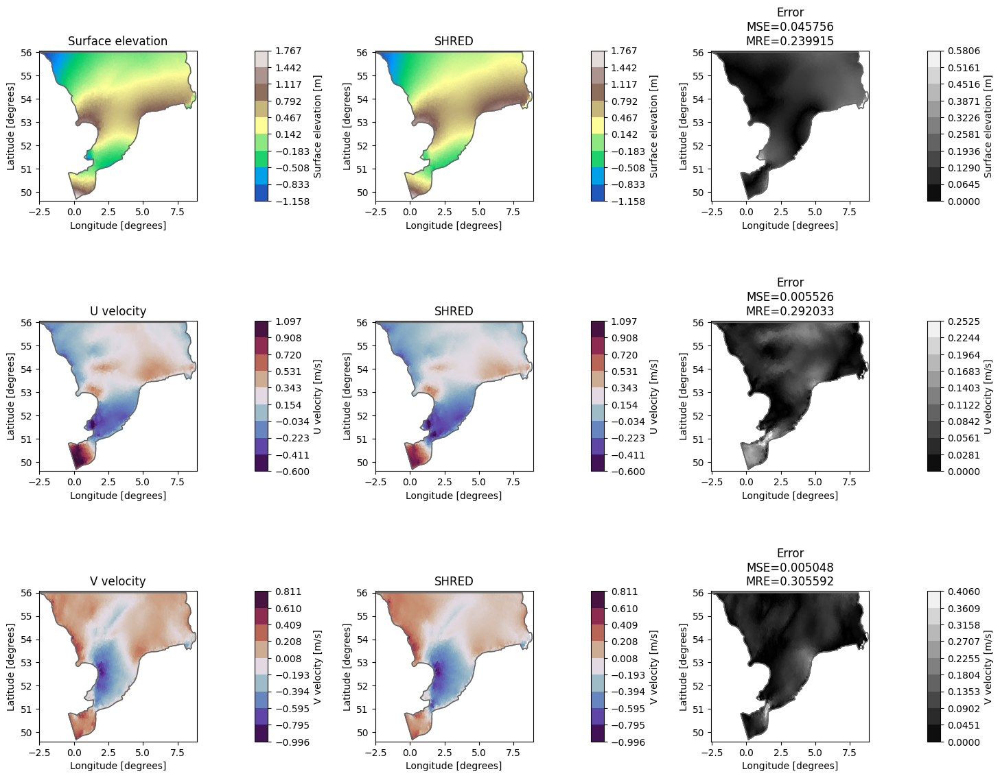

In [35]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred


## Idea 2.B: Attn AGRUD


Starting training...


Training: 100%|██████████| 200/200 [36:47<00:00, 11.04s/it, Train Loss=0.0045, Val Loss=0.0046, Patience=22, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


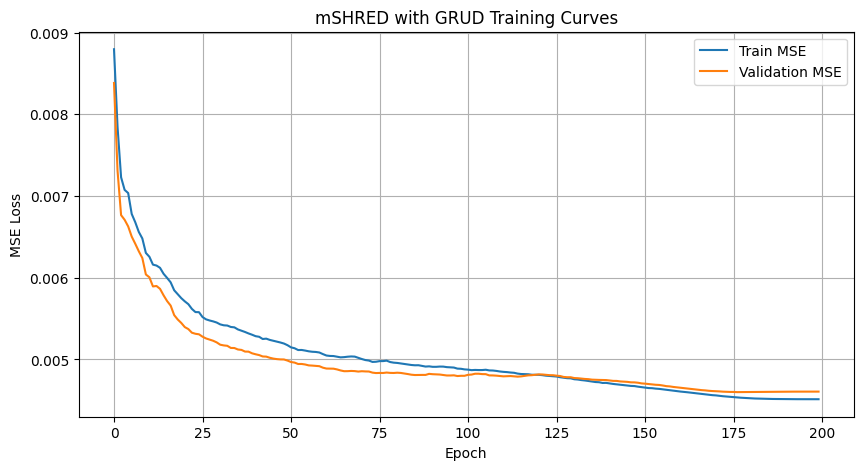

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [36]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


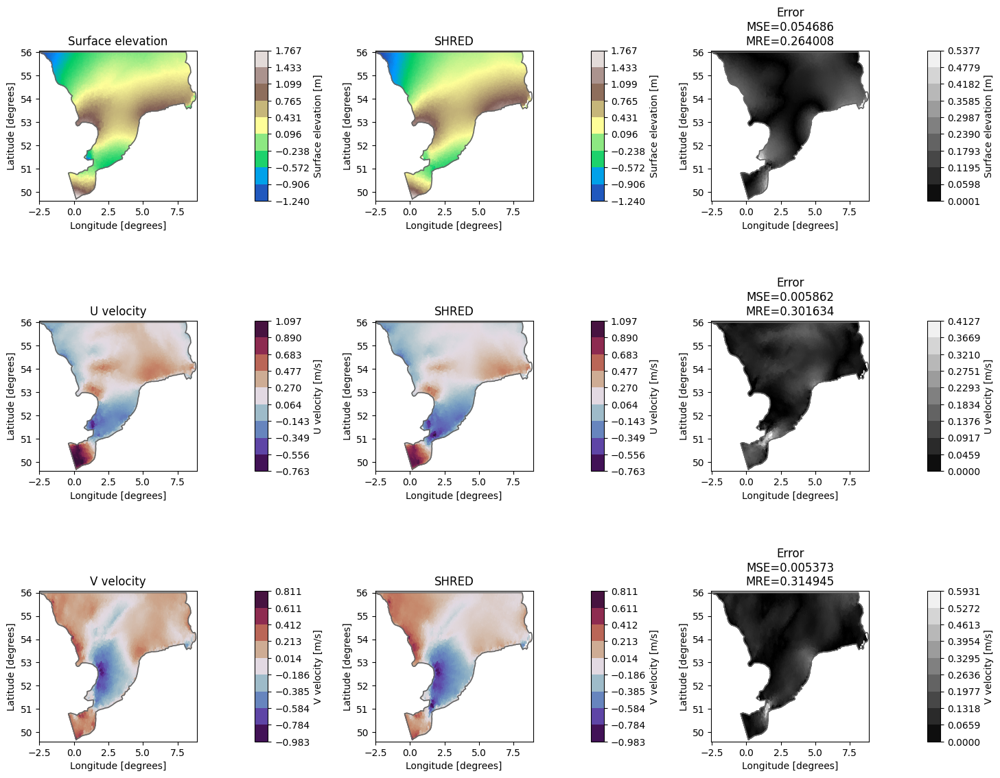

In [37]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager


## Masking

In [38]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 26585 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 26585

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 4]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 4]) -> torch.Size([3504, 120])

Input shape for the model: 4
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training: 100%|██████████| 200/200 [31:51<00:00,  9.56s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=34, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


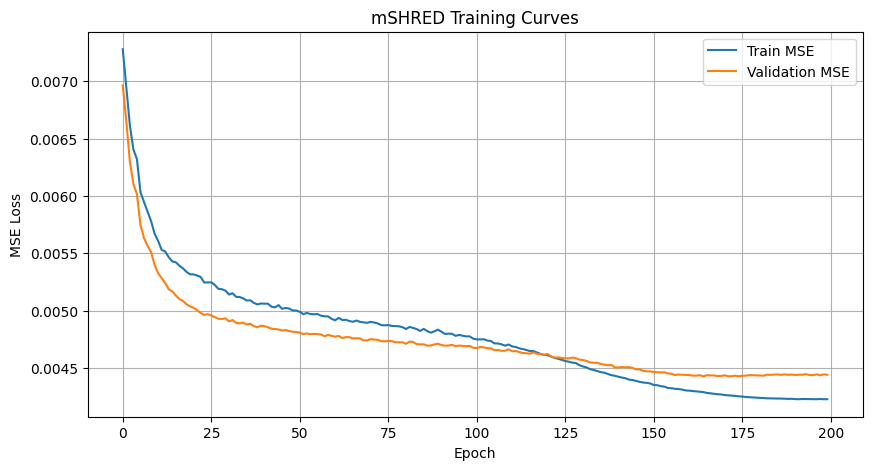

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [39]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


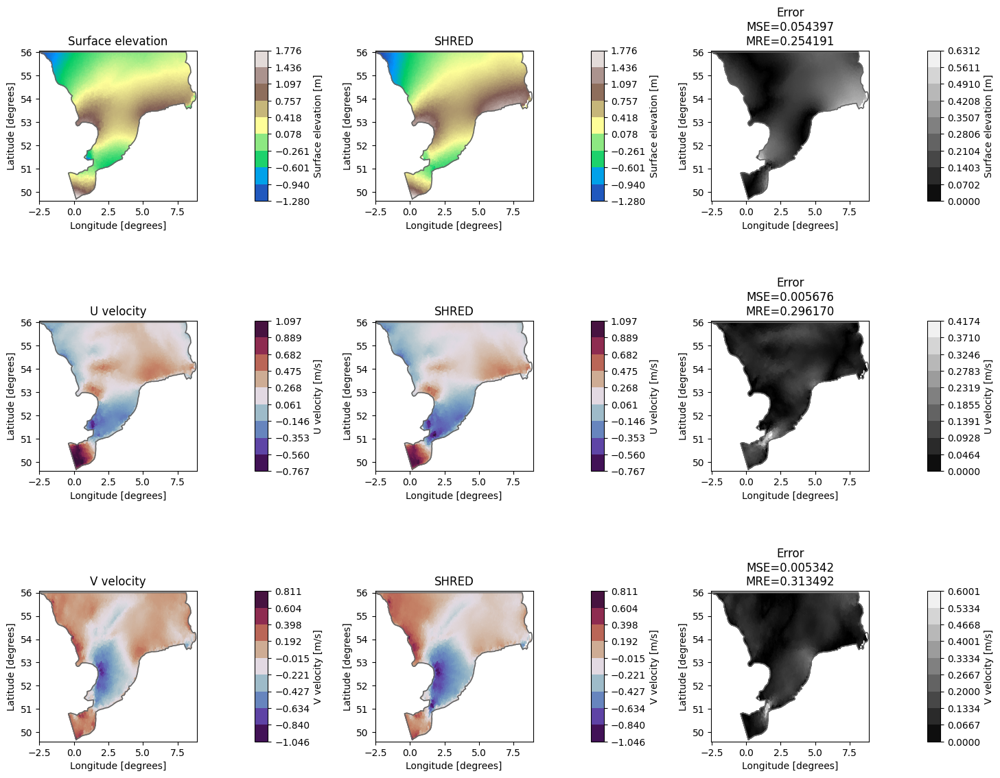

In [40]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.A: Mask double channels

Starting training...


Training: 100%|██████████| 200/200 [31:21<00:00,  9.41s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=21, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


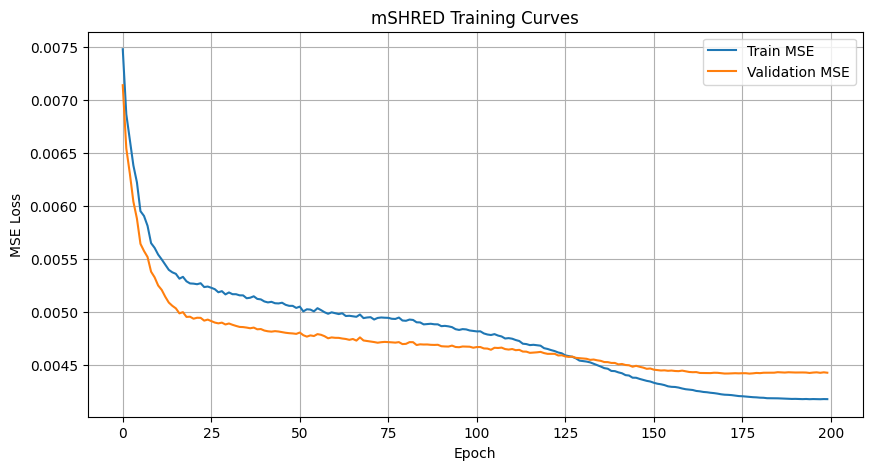

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [41]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


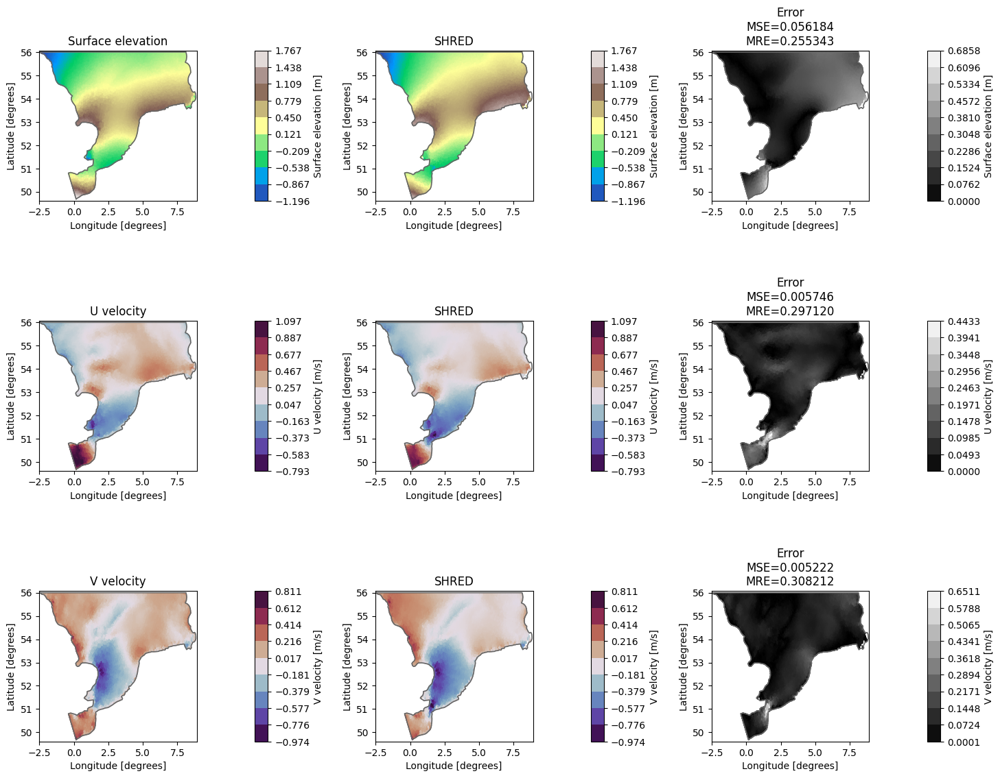

In [42]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 200/200 [32:33<00:00,  9.77s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=8, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


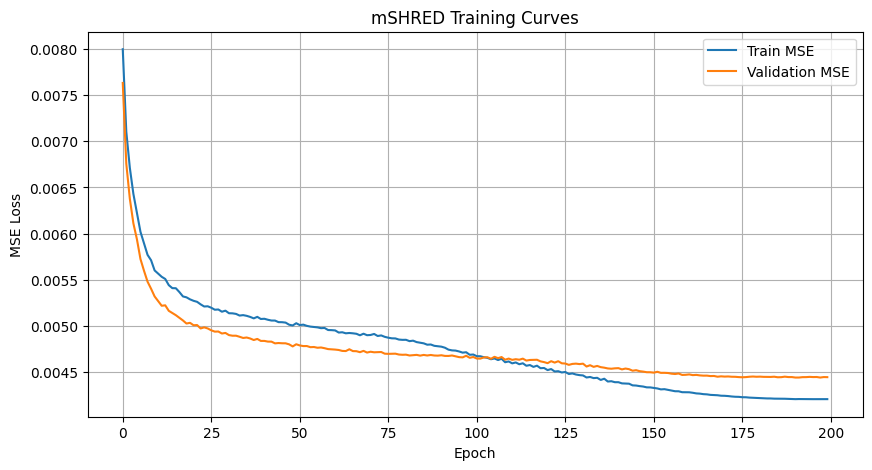

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [43]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


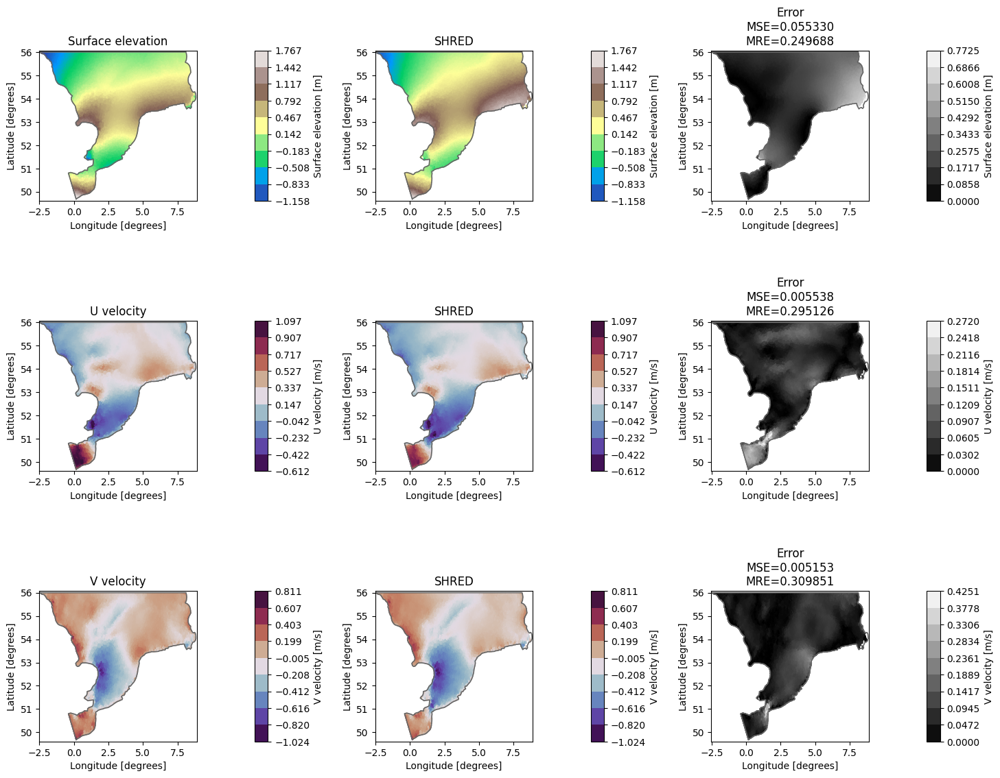

In [44]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 200/200 [32:43<00:00,  9.82s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=3, Best Val Loss=0.0044, LR=0.00e+00] 

Training completed with best validation loss: 0.0044


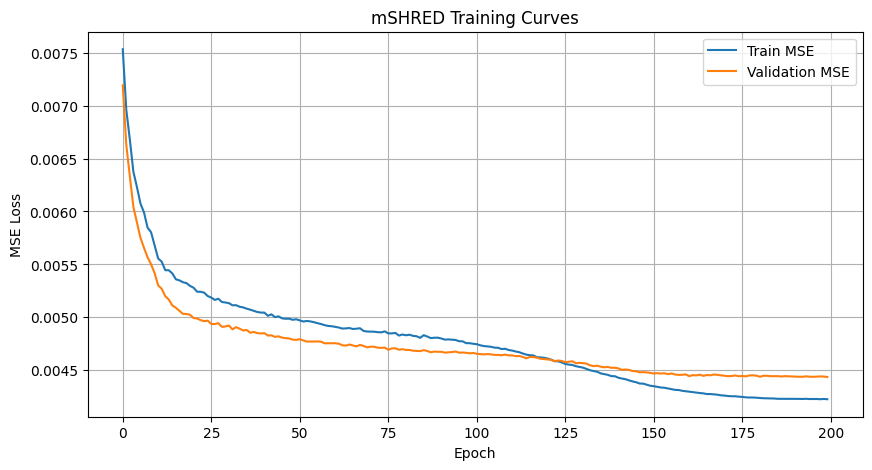

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [45]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


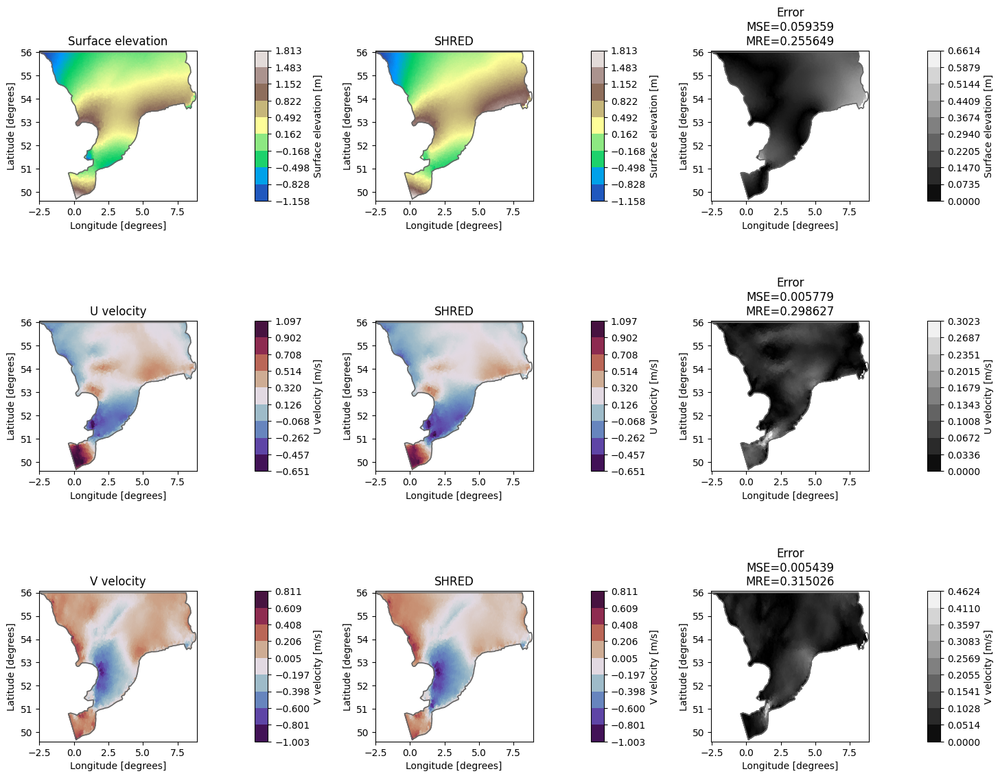

In [46]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.D: Attention mask + double channels

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [31:53<00:00,  9.57s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=11, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


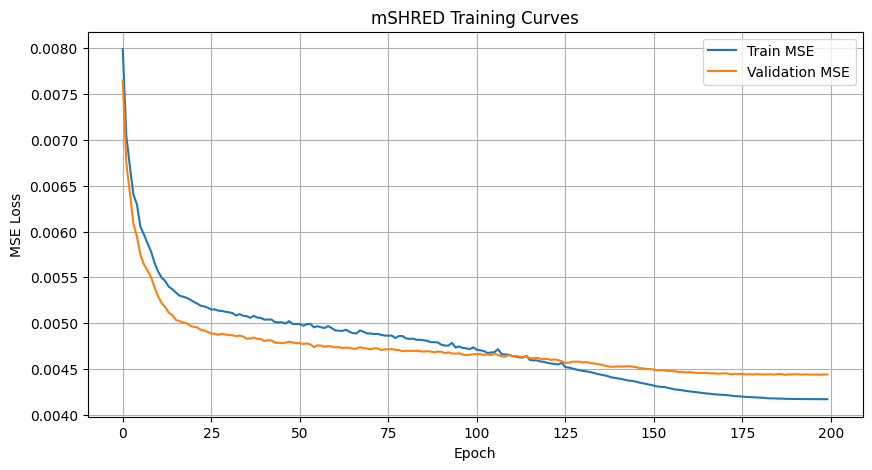

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [47]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


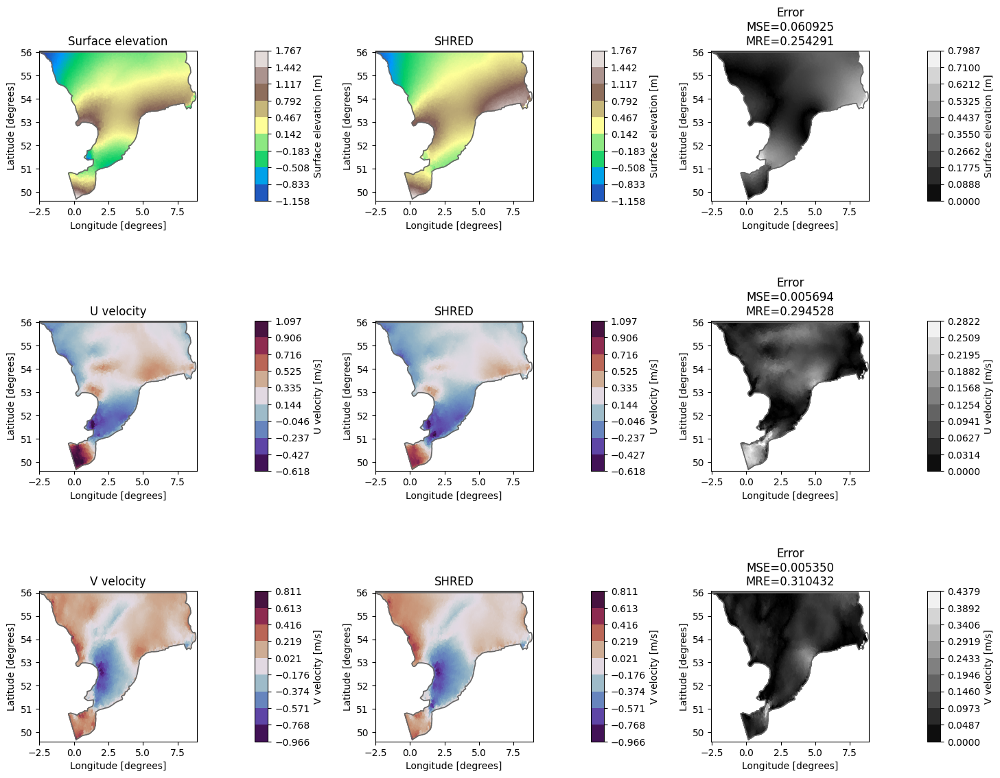

In [48]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.E: learn the mask in the softmax


Starting training...


Training: 100%|██████████| 200/200 [37:58<00:00, 11.39s/it, Train Loss=0.0041, Val Loss=0.0044, Patience=23, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


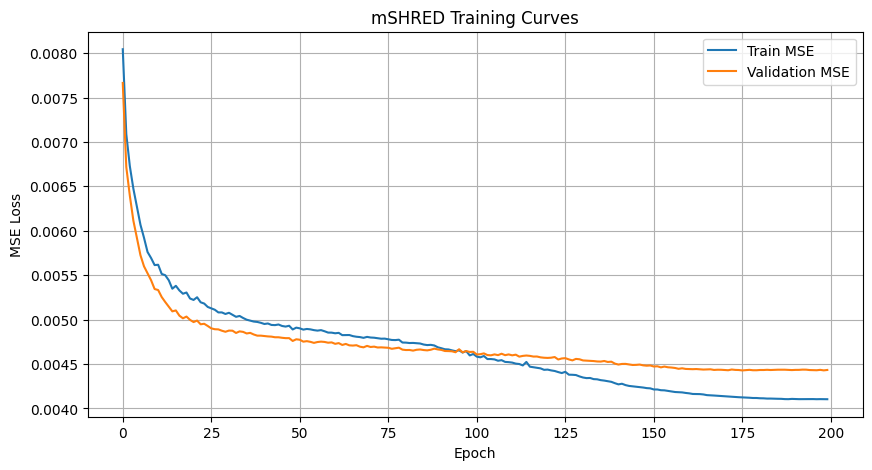

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [49]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


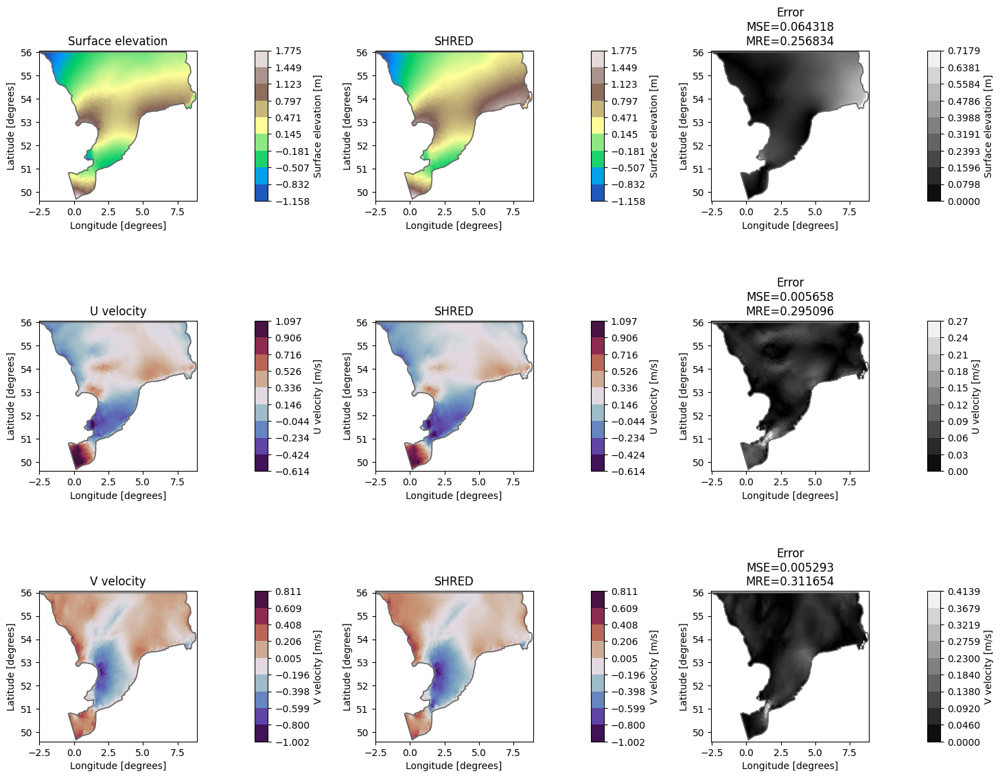

In [50]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.F: Learned mask + double channels


Starting training...


Training: 100%|██████████| 200/200 [38:39<00:00, 11.60s/it, Train Loss=0.0042, Val Loss=0.0044, Patience=26, Best Val Loss=0.0044, LR=0.00e+00]

Training completed with best validation loss: 0.0044


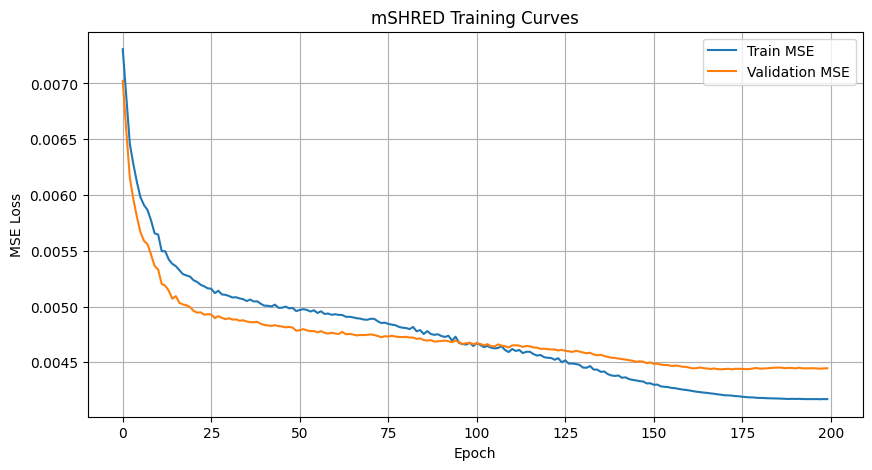

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [51]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


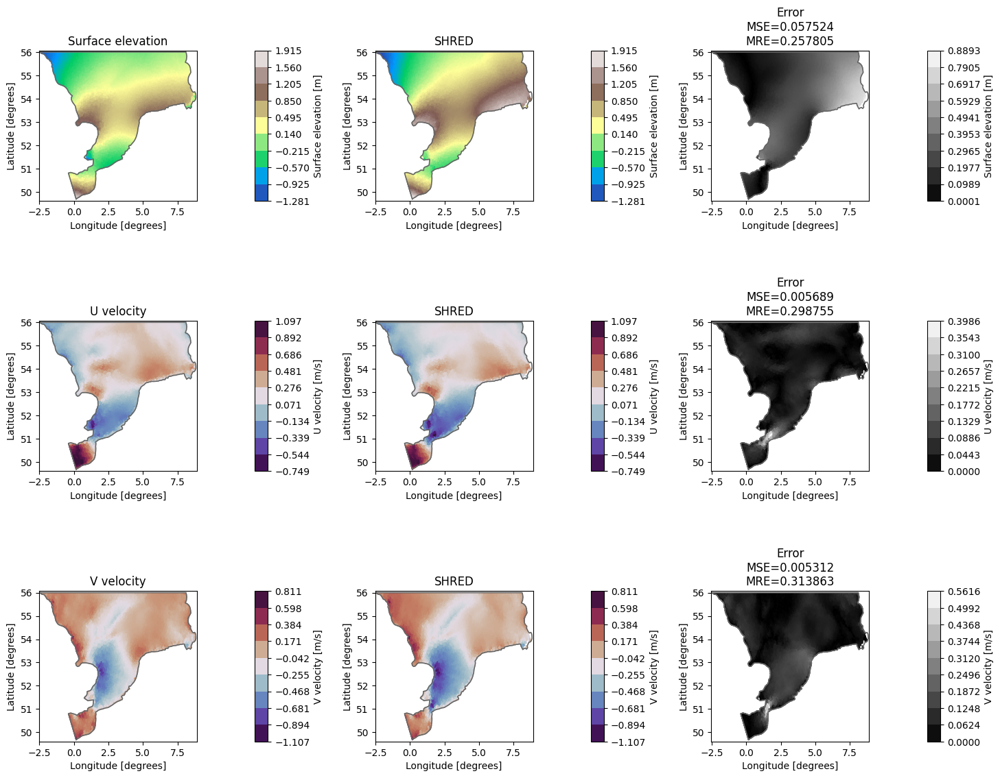

In [52]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Results

In [55]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.004619,0.004693,0.011244,0.135570,0.135086,0.208547
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004421,0.004544,0.010917,0.132310,0.132837,0.205673
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.004476,0.004534,0.010987,0.133549,0.132240,0.206210
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.004437,0.004529,0.010995,0.133299,0.132113,0.206274
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.004416,0.004538,0.010951,0.132784,0.132500,0.206033
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004514,0.004607,0.011030,0.134517,0.134223,0.207052


In [56]:
# order dataframe by test-mse
dataframe_errors = dataframe_errors.sort_values(by="test-mse")
display(dataframe_errors)

# order dataframe by test-mre
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
16,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004170,0.004448,0.010806,0.129234,0.130990,0.204855
15,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004104,0.004435,0.010808,0.128343,0.130708,0.204690
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
10,(mSHRED): TR + MLP,(3.0) TSHRED,0.004228,0.004438,0.010823,0.130073,0.130785,0.204805
12,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004204,0.004440,0.010838,0.129806,0.130646,0.205017
11,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004176,0.004424,0.010847,0.129332,0.130345,0.205069
13,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004228,0.004441,0.010870,0.130080,0.130739,0.205133


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.004202,0.004446,0.010789,0.129818,0.131336,0.203995
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.004288,0.004460,0.010760,0.131088,0.131464,0.204436
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.004310,0.004484,0.010792,0.131304,0.131760,0.204494
15,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004104,0.004435,0.010808,0.128343,0.130708,0.204690
10,(mSHRED): TR + MLP,(3.0) TSHRED,0.004228,0.004438,0.010823,0.130073,0.130785,0.204805
16,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004170,0.004448,0.010806,0.129234,0.130990,0.204855
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004474,0.004511,0.010814,0.133799,0.132489,0.204981
12,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004204,0.004440,0.010838,0.129806,0.130646,0.205017
11,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004176,0.004424,0.010847,0.129332,0.130345,0.205069
13,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004228,0.004441,0.010870,0.130080,0.130739,0.205133


## 